## 10.1 중심성으로 클러스터 발견하기

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
import re
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import warnings
warnings.filterwarnings('ignore')
import unicodedata
import random

plt.rcParams['font.family'] = "AppleGothic"  # 올바른 키
plt.rcParams['axes.unicode_minus'] = False  # 마이너스 기호 깨짐 방지

In [5]:
# code 10 - 1 두 정규 분포를 사용하여 다트 좌표 모델링하기
np.random.seed(0)
mean = 0
variance = 2
x = np.random.normal(mean, variance**0.5)
y = np.random.normal(mean, variance**0.5)
print(f"임으로 던진 다트의 x 좌표는 {x:.2f} 입니다")
print(f"임으로 던진 다트의 y 좌표는 {y:.2f} 입니다")

임으로 던진 다트의 x 좌표는 2.49 입니다
임으로 던진 다트의 y 좌표는 0.57 입니다


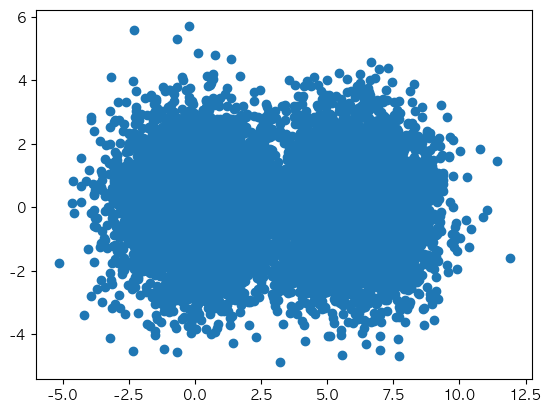

In [11]:
# code 10-2 임으로 덪져진 다트 시뮬레이션
np.random.seed(1)
bulls_eye1 = [0,0]
bulls_eye2 = [6,0]
bulls_eyes = [bulls_eye1, bulls_eye2]
x_coordinates, y_coordinates = [] , []
for bulls_eye in bulls_eyes:
    for _ in range(5000):
        x = np.random.normal(bulls_eye[0] , variance**0.5)
        y = np.random.normal(bulls_eye[1] , variance**0.5)
        x_coordinates.append(x)
        y_coordinates.append(y)
plt.scatter(x_coordinates, y_coordinates)
plt.show()

In [12]:
# code 10-3 가장 가까운 과녁에 다트 할당하기
from scipy.spatial.distance import euclidean
def nearest_bulls_eye(dart):
    distance = [euclidean(dart, bulls_e) for bulls_e in bulls_eyes]
    return np.argmin(distance)

darts = [[0,1],[6,1]]

for dart in darts:
    index = nearest_bulls_eye(dart)
    print(f"위치 {dart}의 다트는 {index} 번째 과녁에서 가장 가깝습니다")

위치 [0, 1]의 다트는 0 번째 과녁에서 가장 가깝습니다
위치 [6, 1]의 다트는 1 번째 과녁에서 가장 가깝습니다


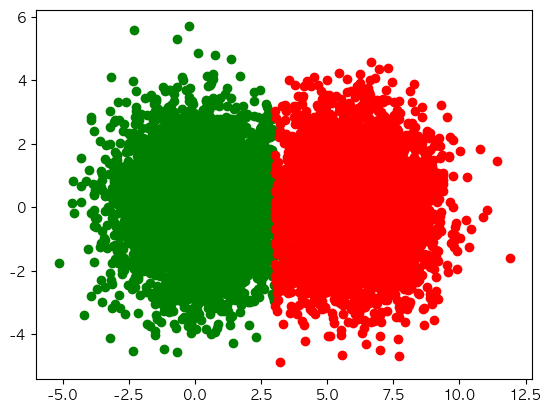

In [15]:
# code 10-4 가장 가까운 과녁을 기준으로 다트 색칠하기

def color_by_cluster(darts):
    nearest_bulls_eyes = [ nearest_bulls_eye(dart) for dart in darts]
    for bs_index in range(len(bulls_eyes)):
        selected_darts = [darts[i] for i in range(len(darts))
                          if bs_index == nearest_bulls_eyes[i]]
        x_coordinates, y_coordinates = np.array(selected_darts).T
        plt.scatter(x_coordinates, y_coordinates, color=['g','r'][bs_index])
    plt.show()

darts = list(zip(x_coordinates, y_coordinates))
color_by_cluster(darts)

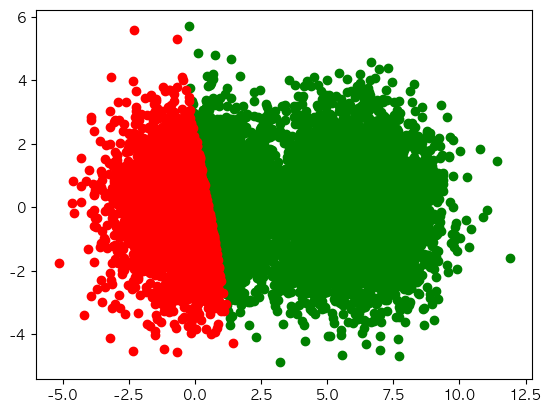

In [16]:
# code 10-5 임의로 선택된 다트 할당하기
bulls_eyes = np.array(darts[:2])
color_by_cluster(darts)